# Prototype – Monthly LULC Maps from Sentinel-1

**Goal:** produce 12 monthly land use / land cover maps for any location, using only Sentinel-1 radar data and the trained U-Net.

**Input:** latitude, longitude and a start month.

**Output:** 12 maps, the share of each class per month, the month-to-month change and the total change (percentage points), and a comparison with Dynamic World. All results are saved in `results_mannheim/`.

## Step 1 – Setup

**What:** load the libraries, connect to Google Earth Engine and load the trained model (`model_best.pt`) with its configuration (`model_config.json`).

**Why:** the configuration contains the normalisation values of the training data, so new data is processed exactly like the training data.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import json
import ee
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
%matplotlib inline

import lulc_prototype as lp

ee.Initialize(project='lulc-bharat-2026')

config = json.load(open('model_config.json'))
CLASSES = config['class_names']
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = lp.load_model('model_best.pt', config, device)
print('Model:', config['variant'], '| classes:', CLASSES, '| device:', device)

Model: unet_resnet34 | classes: ['Tree', 'Grass/Shrub', 'Cropland', 'Built-up', 'Bare/Sparse', 'Water', 'Wetland'] | device: cpu


## Step 2 – Input

**What:** location, start month and size of the area.

**Case study:** Mannheim city centre (49.4875° N, 8.4660° E), start month January 2025, 10 km × 10 km. Mannheim was not used in training, validation or testing.

In [2]:
LAT, LON = 49.4875, 8.4660
START    = '2025-01'
SIZE_KM  = 10

months = lp.month_list(START)
grid, region = lp.make_grid(LAT, LON, SIZE_KM, config['scale_m'], config['crs'])
print(f'Area: {SIZE_KM} x {SIZE_KM} km around ({LAT}, {LON})')
print('Months:', months)

Area: 10 x 10 km around (49.4875, 8.466)
Months: ['2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12']


## Step 3 – Data retrieval, monthly composites and prediction

**What:** for each of the 12 months:
1. take all Sentinel-1 scenes (VV, VH) of the month from Earth Engine,
2. mask border noise, apply a 3 × 3 median speckle filter and build the monthly median composite (plus VV−VH),
3. normalise it and predict the land-cover map with the U-Net,
4. download the Dynamic World map of the same month as an independent reference.

**Why:** this is the same preprocessing as for the training data. The area is sampled on a 10 m grid in EPSG:3035 (equal-area), so every pixel covers the same area.

In [3]:
maps, dw_maps, log = [], [], []
for m in months:
    img, n = lp.s1_monthly_composite(region, m)
    n = n.getInfo()
    if n == 0:
        print(f'{m}: no Sentinel-1 scenes')
        maps.append(None); dw_maps.append(None); log.append(dict(month=m, s1_scenes=0))
        continue
    x = lp.download(img.unmask(-50), config['band_order'], grid)          # (3, H, W) in dB
    pred = lp.predict(model, x, config, device)                           # (H, W) class map
    maps.append(pred)

    dw, n_dw = lp.dynamic_world_month(region, m)
    n_dw = n_dw.getInfo()
    dw_map = lp.download(dw.unmask(lp.IGNORE), ['dw'], grid)[0].astype(np.uint8) if n_dw > 0 else None
    dw_maps.append(dw_map)
    oa, miou = lp.agreement(pred, dw_map, len(CLASSES)) if dw_map is not None else (np.nan, np.nan)
    log.append(dict(month=m, s1_scenes=n, dw_images=n_dw, agreement_OA=round(oa, 3), agreement_mIoU=round(miou, 3)))
    print(f'{m}: {n:2d} Sentinel-1 scenes | agreement with Dynamic World: OA {oa:.3f}')

log = pd.DataFrame(log)
log

2025-01:  8 Sentinel-1 scenes | agreement with Dynamic World: OA 0.666
2025-02:  7 Sentinel-1 scenes | agreement with Dynamic World: OA 0.783
2025-03:  8 Sentinel-1 scenes | agreement with Dynamic World: OA 0.777
2025-04:  7 Sentinel-1 scenes | agreement with Dynamic World: OA 0.792
2025-05: 15 Sentinel-1 scenes | agreement with Dynamic World: OA 0.765
2025-06: 15 Sentinel-1 scenes | agreement with Dynamic World: OA 0.754
2025-07: 16 Sentinel-1 scenes | agreement with Dynamic World: OA 0.757
2025-08: 15 Sentinel-1 scenes | agreement with Dynamic World: OA 0.779
2025-09: 16 Sentinel-1 scenes | agreement with Dynamic World: OA 0.770
2025-10: 15 Sentinel-1 scenes | agreement with Dynamic World: OA 0.768
2025-11: 14 Sentinel-1 scenes | agreement with Dynamic World: OA nan
2025-12: 16 Sentinel-1 scenes | agreement with Dynamic World: OA 0.686


,month,s1_scenes,dw_images,agreement_OA,agreement_mIoU
0,2025-01,8,3,0.666,0.378
1,2025-02,7,2,0.783,0.353
2,2025-03,8,6,0.777,0.427
3,2025-04,7,10,0.792,0.358
4,2025-05,15,7,0.765,0.352
5,2025-06,15,10,0.754,0.331
6,2025-07,16,3,0.757,0.338
7,2025-08,15,8,0.779,0.381
8,2025-09,16,1,0.770,0.376
9,2025-10,15,3,0.768,0.366


## Step 4 – The 12 monthly LULC maps

**Output:** `results_mannheim/lulc_maps_12_months.png`

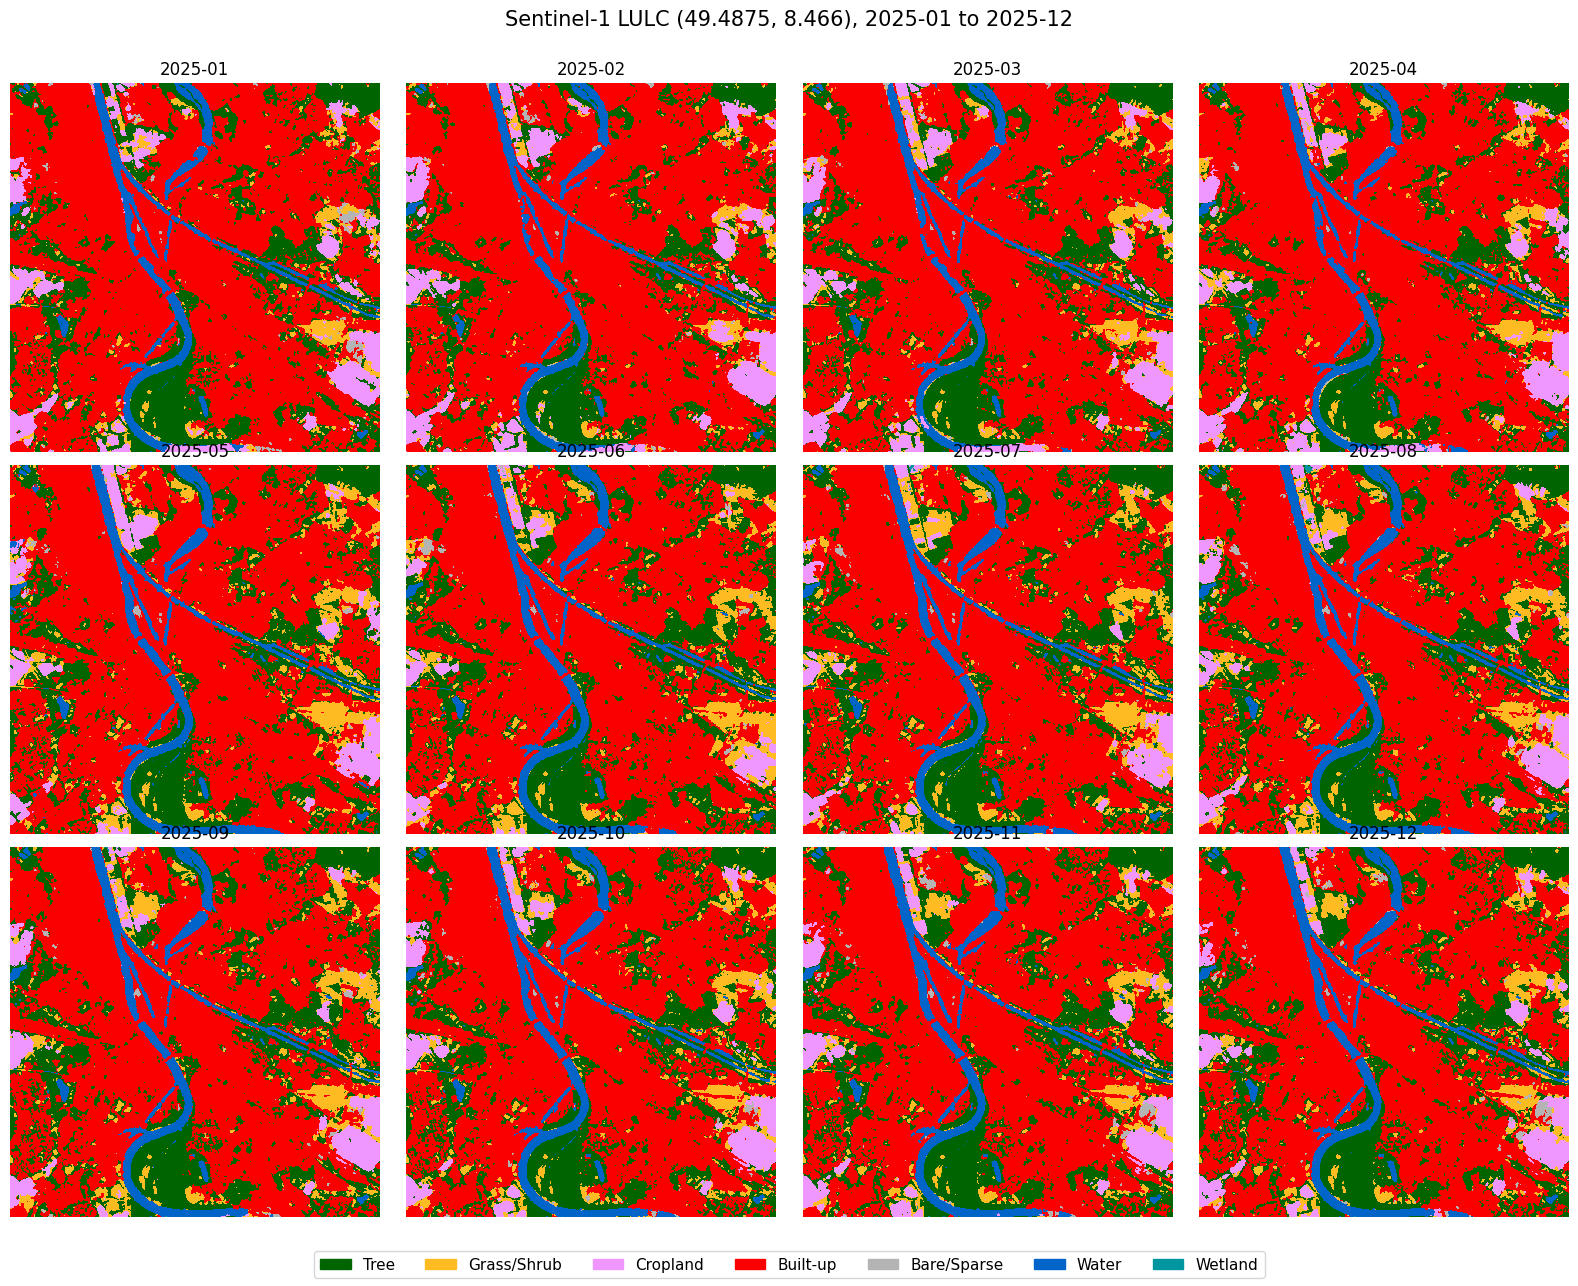

In [4]:
import os
os.makedirs('results_mannheim', exist_ok=True)
lp.plot_maps(maps, months, config, f'Sentinel-1 LULC ({LAT}, {LON}), {months[0]} to {months[-1]}',
             'results_mannheim/lulc_maps_12_months.png')

## Step 5 – Share of each class per month

**What:** % of the valid area covered by each class in each month.

In [5]:
pct = lp.class_percentages(maps, months, CLASSES)
pct.round(2)

,Tree,Grass/Shrub,Cropland,Built-up,Bare/Sparse,Water,Wetland
2025-01,20.86,3.98,6.10,62.90,0.68,5.49,0.00
2025-02,18.34,3.25,7.36,65.11,0.39,5.56,0.00
2025-03,20.27,4.80,6.55,62.75,0.34,5.29,0.00
2025-04,19.33,4.96,5.87,64.01,0.25,5.57,0.00
2025-05,21.13,6.68,4.57,60.58,0.28,6.75,0.00
2025-06,23.11,7.22,2.70,59.99,0.40,6.58,0.00
2025-07,22.04,7.54,3.29,60.19,0.35,6.56,0.03
2025-08,22.15,7.01,4.13,59.64,0.38,6.64,0.05
2025-09,23.49,6.57,4.20,59.14,0.36,6.22,0.01
2025-10,23.11,6.00,4.98,59.05,0.42,6.44,0.00


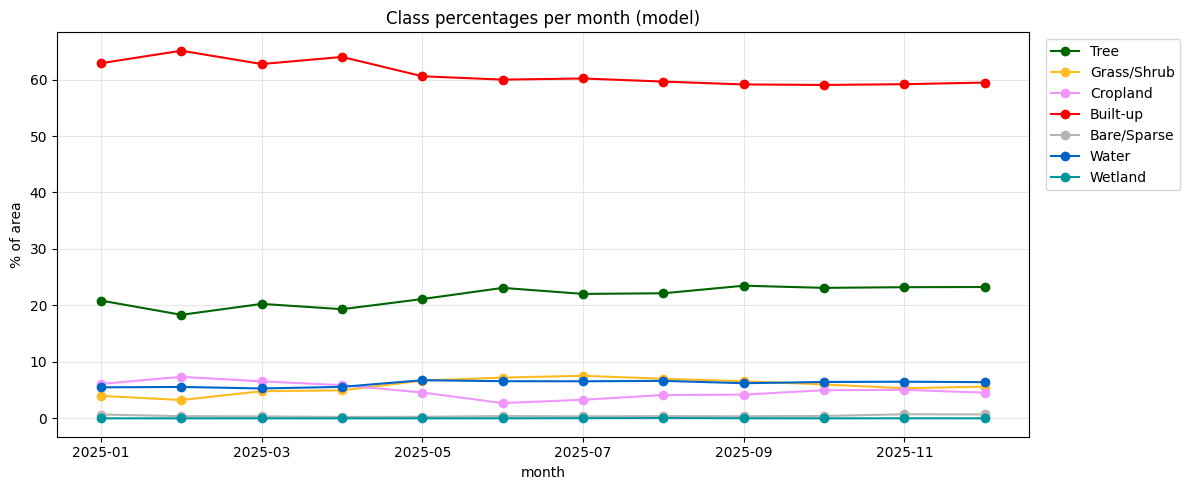

In [6]:
lp.plot_percentages(pct, config, 'Class percentages per month (model)', 'results_mannheim/class_percentages.png')

## Step 6 – Month-to-month change and total change

**What:** difference of the class shares between consecutive months, and between the first and the last month, in **percentage points (pp)**.

**Why percentage points:** a change from 20 % to 23 % is +3 pp; reporting pp avoids confusion with relative changes.

In [7]:
mom, total = lp.changes(pct)
mom.round(2)

,Tree,Grass/Shrub,Cropland,Built-up,Bare/Sparse,Water,Wetland
2025-01 -> 2025-02,-2.52,-0.73,1.26,2.21,-0.29,0.07,-0.00
2025-02 -> 2025-03,1.93,1.55,-0.81,-2.36,-0.05,-0.27,-0.00
2025-03 -> 2025-04,-0.93,0.15,-0.67,1.26,-0.09,0.28,0.00
2025-04 -> 2025-05,1.80,1.72,-1.30,-3.43,0.03,1.18,0.00
2025-05 -> 2025-06,1.98,0.54,-1.87,-0.59,0.12,-0.18,0.00
2025-06 -> 2025-07,-1.07,0.32,0.59,0.20,-0.05,-0.02,0.02
2025-07 -> 2025-08,0.11,-0.53,0.84,-0.55,0.03,0.08,0.02
2025-08 -> 2025-09,1.34,-0.43,0.07,-0.50,-0.02,-0.42,-0.04
2025-09 -> 2025-10,-0.38,-0.57,0.78,-0.09,0.06,0.22,-0.01
2025-10 -> 2025-11,0.12,-0.67,0.07,0.13,0.30,0.05,0.00


In [8]:
total.round(2).to_frame('total change (pp)')

,total change (pp)
Tree,2.40
Grass/Shrub,1.64
Cropland,-1.54
Built-up,-3.44
Bare/Sparse,0.02
Water,0.92
Wetland,0.00


## Step 7 – Sanity check against Dynamic World

**What:** compare the model with Google Dynamic World, an independent LULC map based on Sentinel-2 optical data that was **not used for training**.

**Note:** months without usable Dynamic World data (cloud cover in the optical images) appear empty (white); the Sentinel-1 model is not affected by clouds.

**Output:** `results_mannheim/dynamic_world_12_months.png`

In [9]:
dw_pct = lp.class_percentages(dw_maps, months, CLASSES)
_, dw_total = lp.changes(dw_pct)
comparison = pd.DataFrame({'model mean %': pct.mean(), 'Dynamic World mean %': dw_pct.mean(),
                           'model total change pp': total, 'Dynamic World total change pp': dw_total}).round(2)
comparison

,model mean %,Dynamic World mean %,model total change pp,Dynamic World total change pp
Tree,21.69,8.60,2.40,3.71
Grass/Shrub,5.75,3.58,1.64,-2.09
Cropland,4.95,7.21,-1.54,-1.63
Built-up,61.00,70.83,-3.44,4.57
Bare/Sparse,0.44,1.86,0.02,-1.69
Water,6.17,7.91,0.92,-2.87
Wetland,0.01,0.02,0.00,0.00


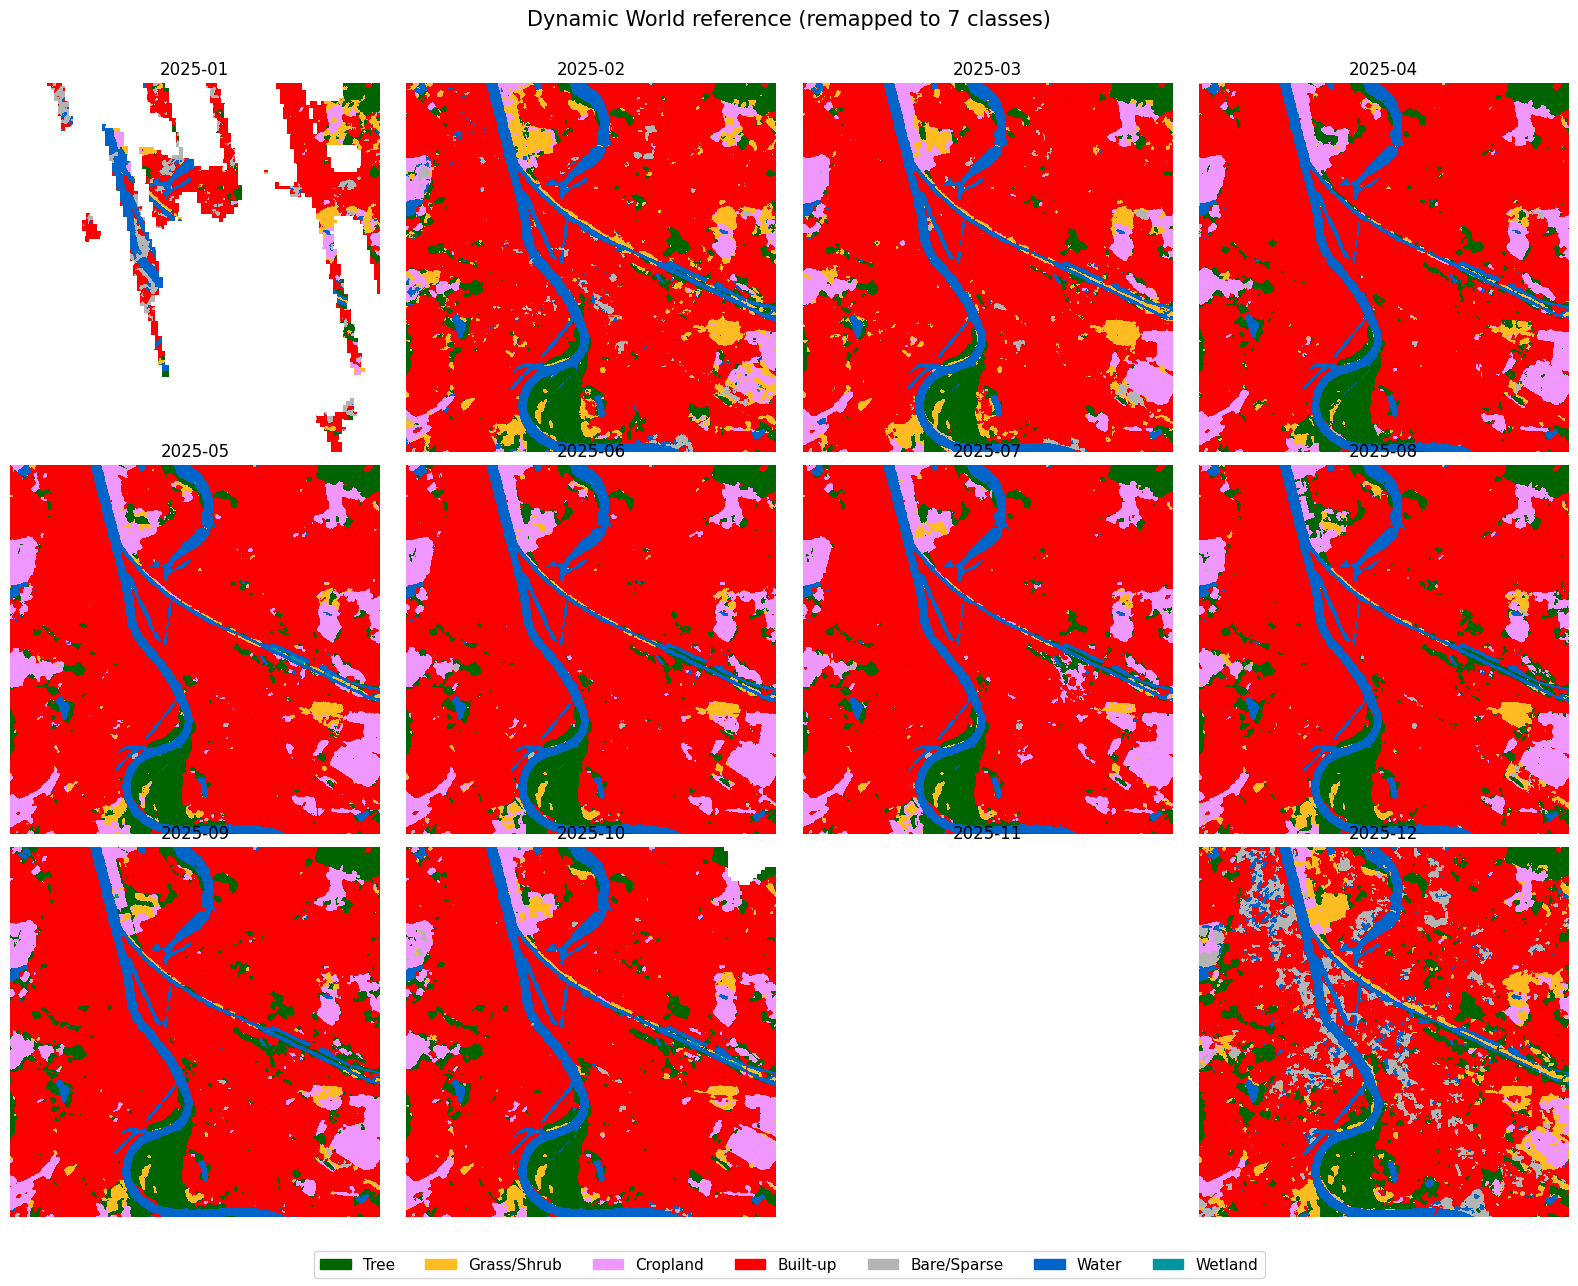

In [10]:
lp.plot_maps(dw_maps, months, config, 'Dynamic World reference (remapped to 7 classes)',
             'results_mannheim/dynamic_world_12_months.png')

## Step 8 – Save results

**Output:** CSV tables in `results_mannheim/` (class percentages, changes, Dynamic World comparison, run log).

In [11]:
pct.round(2).to_csv('results_mannheim/class_percentages.csv')
mom.round(2).to_csv('results_mannheim/change_month_to_month_pp.csv')
total.round(2).to_csv('results_mannheim/change_total_pp.csv')
dw_pct.round(2).to_csv('results_mannheim/dynamic_world_percentages.csv')
comparison.to_csv('results_mannheim/comparison_dynamic_world.csv')
log.to_csv('results_mannheim/run_log.csv', index=False)
print('Saved:', sorted(os.listdir('results_mannheim')))

Saved: ['change_month_to_month_pp.csv', 'change_total_pp.csv', 'class_percentages.csv', 'class_percentages.png', 'comparison_dynamic_world.csv', 'dynamic_world_12_months.png', 'dynamic_world_percentages.csv', 'lulc_maps.npz', 'lulc_maps_12_months.png', 'run_log.csv']
